<a href="https://colab.research.google.com/github/mayank261193/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP5_StuntingRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MP5 · What Moves Child Stunting?
**Linear regression on NFHS-5 (2019-21) district data**

Target: `stunted_children_pct`. Run **Runtime → Restart and run all** before submitting. Cells marked ✍️ are for your own written answers, based on the numbers printed above them.

In [24]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error



df = pd.read_csv("mp5_nfhs5_district_health.csv")
TARGET = "stunted_children_pct"
sns.set_theme(style="whitegrid")

## Part 1 · Load and understand the data

In [25]:
# First Rows , shape  with data types of  coloumn heads
print(df.head())
print("\nShape:", df.shape)
print("\nColumn types:\n", df.dtypes)

                       state                district  stunted_children_pct  wasted_children_pct  underweight_children_pct  women_10yrs_school_pct  women_literate_pct  child_marriage_pct  \
0  Andaman & Nicobar Islands                 Nicobar                  21.6                 15.7                      24.6                    53.5                87.5                11.4   
1  Andaman & Nicobar Islands  North & Middle Andaman                  27.0                 27.0                      42.8                    41.0                84.0                15.4   
2  Andaman & Nicobar Islands           South Andaman                  21.1                 12.6                      17.4                    57.5                86.7                17.1   
3             Andhra Pradesh               Anantapur                  36.0                 19.3                      40.6                    31.3                63.6                37.3   
4             Andhra Pradesh                Chittoor   

In [26]:
# Maximum and Minimum of Each Coloumn
pd.set_option("display.width", 200)
df.describe().T[["min","max","mean"]]

,min,max,mean
stunted_children_pct,0.0,60.6,33.463791
wasted_children_pct,0.0,48.0,18.511881
underweight_children_pct,0.0,62.4,29.460113
women_10yrs_school_pct,0.0,88.2,40.267185
women_literate_pct,0.0,99.7,72.984017
child_marriage_pct,0.0,80.9,20.637058
improved_sanitation_pct,0.0,99.9,71.843989
improved_water_pct,0.0,100.0,93.646959
clean_cooking_fuel_pct,0.0,99.8,54.092221
electricity_pct,0.0,100.0,96.868883


In [27]:
# Count Zeroes in coloumn
zeros = (df == 0).sum()   # count all zeroes at once
print("Zeros per column:\n", zeros[zeros > 0])
print("\n'Data Not Available' row:")
df[df["district"].str.strip().str.lower() == "data not available"]

Zeros per column:
 stunted_children_pct          1
wasted_children_pct           1
underweight_children_pct      1
women_10yrs_school_pct        1
women_literate_pct            1
child_marriage_pct            2
improved_sanitation_pct       1
improved_water_pct            1
clean_cooking_fuel_pct        1
electricity_pct               1
institutional_births_pct      1
full_vaccination_pct         14
anc_4visits_pct               1
health_insurance_pct          1
adequate_diet_pct             7
anaemic_children_pct          1
anaemic_women_pct             1
women_low_bmi_pct             1
teen_pregnancy_pct           18
is_aspirational             595
dtype: int64

'Data Not Available' row:


,state,district,stunted_children_pct,wasted_children_pct,underweight_children_pct,women_10yrs_school_pct,women_literate_pct,child_marriage_pct,improved_sanitation_pct,improved_water_pct,...,institutional_births_pct,full_vaccination_pct,anc_4visits_pct,health_insurance_pct,adequate_diet_pct,anaemic_children_pct,anaemic_women_pct,women_low_bmi_pct,teen_pregnancy_pct,is_aspirational
211,Jammu & Kashmir,Data Not Available,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [28]:
pct_cols = list(df.columns[2:-1])
print("Values above 100% (impossible for a percentage):")
over = (df[pct_cols] > 100).sum()
print(over[over > 0])
df.loc[(df[pct_cols] > 100).any(axis=1), ["state","district"] + [c for c in pct_cols if (df[c] > 100).any()]]

Values above 100% (impossible for a percentage):
Series([], dtype: int64)


,state,district


**What will I clean, and why?**

The file has 707 rows, but one ("Data Not Available", in Jammu & Kashmir) is not a real district: every value in it is 0. I will drop it. Across the percentage columns there are also real zeros that mean "not reported": for example 14 in `full_vaccination_pct`, 18 in `teen_pregnancy_pct` and 7 in `adequate_diet_pct`. No district has 0% of any of these, so I will turn them into missing values; otherwise they would pull the regression lines down.

## Part 2 · Clean the data

In [29]:
df = df[df["district"].str.strip().str.lower() != "data not available"].copy()
df[pct_cols] = df[pct_cols].replace(0, np.nan)

# impossible values (>100%) -> missing
n_bad = int((df[pct_cols] > 100).sum().sum())
df[pct_cols] = df[pct_cols].mask(df[pct_cols] > 100)
print("Values above 100 set to NaN:", n_bad)

print("\nTop teen_pregnancy_pct values:")
print(df[["state","district","teen_pregnancy_pct"]].sort_values("teen_pregnancy_pct", ascending=False).head(8))

Values above 100 set to NaN: 0

Top teen_pregnancy_pct values:
           state           district  teen_pregnancy_pct
107   Chandigarh         Chandigarh                91.9
297  Lakshadweep        Lakshadweep                80.3
694  West Bengal         Koch Bihar                27.3
591      Tripura             Dhalai                26.9
595      Tripura         Sepahijala                26.6
701  West Bengal  Paschim Medinipur                25.0
688  West Bengal            Birbhum                25.0
592      Tripura             Gomati                24.4


In [30]:
print("Shape after cleaning:", df.shape)
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])

Shape after cleaning: (706, 22)

Missing values:
 child_marriage_pct       1
full_vaccination_pct    13
adequate_diet_pct        6
teen_pregnancy_pct      17
dtype: int64


**Teen pregnancy top values:** Chandigarh (91.9%) and Lakshadweep (80.3%) are not believable. The next highest district is 27.3%, and real rates elsewhere are mostly in single digits to the 20s. These two look like data-entry or unit errors. I do not use this column as a feature, so they do not affect the models, but I would not trust them in any other analysis, and I would set them to missing if I used the column.

## Part 3 · Explore before you model

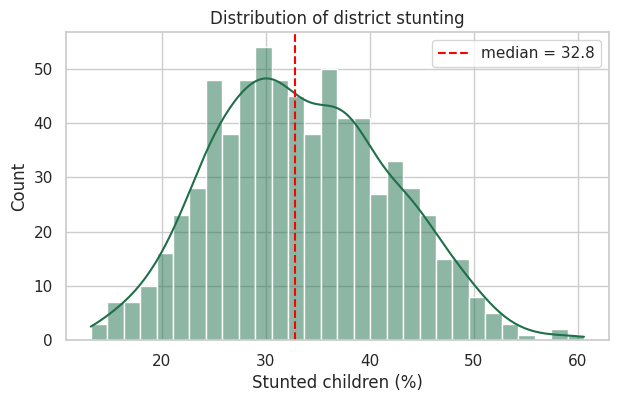

Mean: 33.5  Median: 32.8  Skew: 0.21


In [31]:
plt.figure(figsize=(7,4))
sns.histplot(df[TARGET].dropna(), bins=30, kde=True, color="#1f6f4a")
plt.axvline(df[TARGET].median(), color="red", ls="--", label=f"median = {df[TARGET].median():.1f}")
plt.xlabel("Stunted children (%)"); plt.title("Distribution of district stunting"); plt.legend(); plt.show()
print("Mean:", round(df[TARGET].mean(),1), " Median:", round(df[TARGET].median(),1), " Skew:", round(df[TARGET].skew(),2))

**Histogram comment:** The typical district has about 33% of children stunted (mean 33.5, median 32.8), which matches the "one in three" in the brief. The shape is close to symmetric with a very slight right skew (skew = 0.21), and there is a long spread from roughly 10% to 60%.

In [32]:
corr = df.corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
print(corr)
print("\nThree strongest (by absolute value), all columns:")
print(corr.reindex(corr.abs().sort_values(ascending=False).index).head(3))

outcomes = ["wasted_children_pct", "underweight_children_pct"]   # outcomes, not causes/factors
factor_corr = corr.drop(outcomes)
print("\nThree strongest excluding the other two nutrition outcomes:")
print(factor_corr.reindex(factor_corr.abs().sort_values(ascending=False).index).head(3))

women_10yrs_school_pct     -0.540876
women_literate_pct         -0.538993
improved_sanitation_pct    -0.502898
electricity_pct            -0.427657
clean_cooking_fuel_pct     -0.412485
institutional_births_pct   -0.380700
anc_4visits_pct            -0.360826
adequate_diet_pct          -0.234880
full_vaccination_pct       -0.195079
health_insurance_pct       -0.121148
improved_water_pct         -0.037207
teen_pregnancy_pct          0.146764
anaemic_women_pct           0.238045
wasted_children_pct         0.238255
is_aspirational             0.298902
anaemic_children_pct        0.331509
child_marriage_pct          0.426367
women_low_bmi_pct           0.552092
underweight_children_pct    0.701788
Name: stunted_children_pct, dtype: float64

Three strongest (by absolute value), all columns:
underweight_children_pct    0.701788
women_low_bmi_pct           0.552092
women_10yrs_school_pct     -0.540876
Name: stunted_children_pct, dtype: float64

Three strongest excluding the other two nutritio

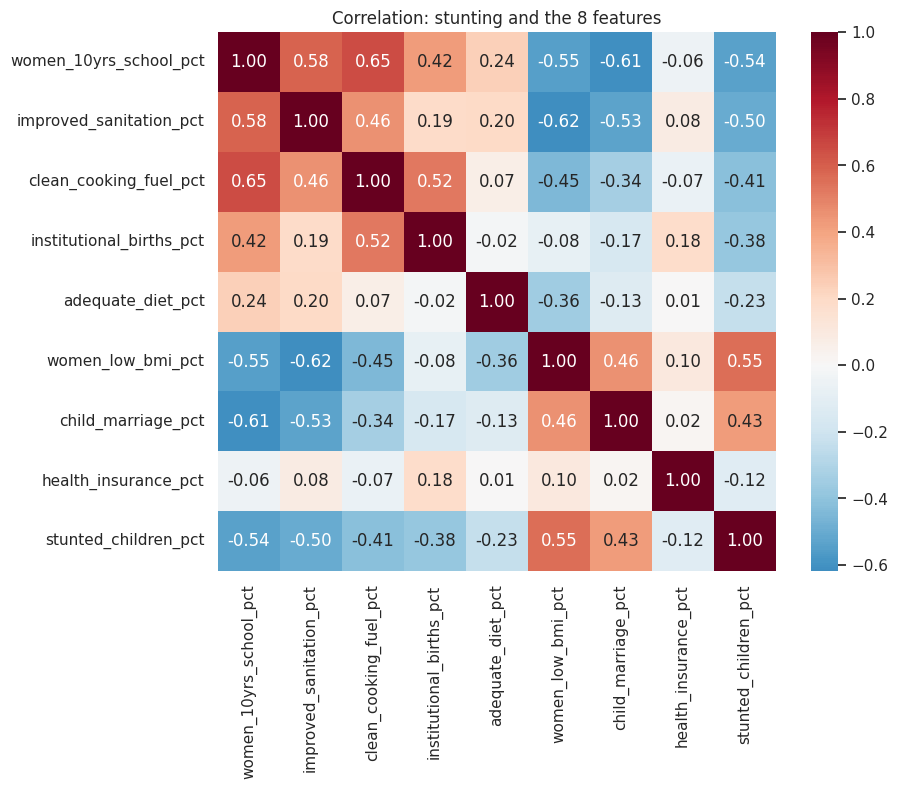

In [33]:
features = ["women_10yrs_school_pct", "improved_sanitation_pct",
            "clean_cooking_fuel_pct", "institutional_births_pct",
            "adequate_diet_pct", "women_low_bmi_pct",
            "child_marriage_pct", "health_insurance_pct"]
plt.figure(figsize=(9,7))
sns.heatmap(df[features + [TARGET]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation: stunting and the 8 features"); plt.show()

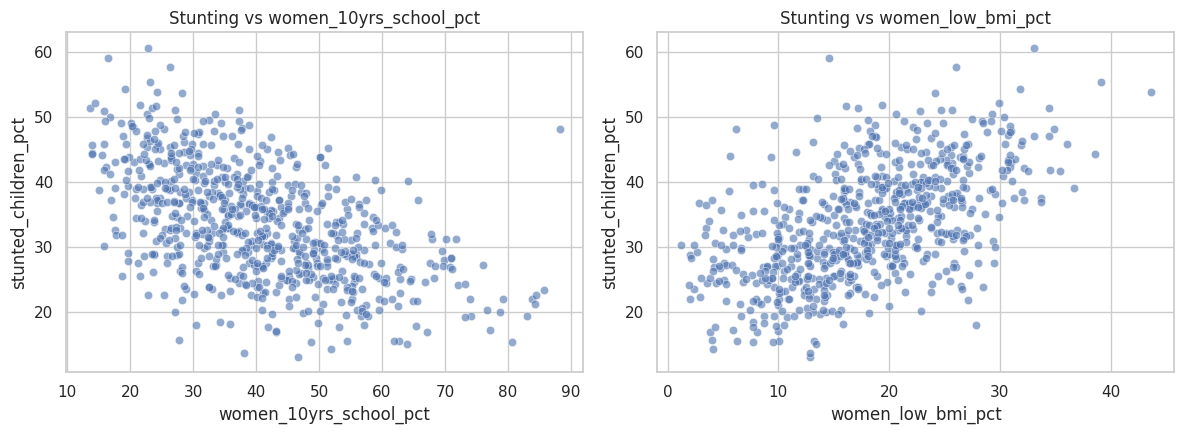

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
for a, col in zip(ax, ["women_10yrs_school_pct", "women_low_bmi_pct"]):
    sns.scatterplot(data=df, x=col, y=TARGET, ax=a, alpha=0.6)
    a.set_title(f"Stunting vs {col}")
plt.tight_layout(); plt.show()

**Scatter comments:** Stunting falls as women's schooling rises (correlation about -0.54) and rises as women's low BMI rises (about +0.55). Both are clear trends but loose clouds, not tight lines, so schooling or BMI alone cannot predict a district well. The three strongest correlations overall are underweight children (+0.70), women's low BMI (+0.55) and women's schooling (-0.54). Underweight is another child-nutrition outcome, so it is not a real "factor": excluding it, low BMI and schooling are the top two.

## Part 4 · Simple regression: one factor

In [35]:
f1 = "women_10yrs_school_pct"
d1 = df.dropna(subset=[f1, TARGET])
X = d1[[f1]]; y = d1[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42)

m1 = LinearRegression().fit(X_train, y_train)
print("Coefficient:", round(m1.coef_[0], 4), " Intercept:", round(m1.intercept_, 3))
pred1 = m1.predict(X_test)
r2_1 = r2_score(y_test, pred1); rmse_1 = mean_squared_error(y_test, pred1) ** 0.5
print(f"Rows used: {len(d1)}   Test R²: {r2_1:.3f}   Test RMSE: {rmse_1:.2f}")
print(f"\nFor every 10 more percentage points of women with 10+ years of schooling, "
      f"stunting is about {abs(m1.coef_[0]*10):.1f} points {'lower' if m1.coef_[0] < 0 else 'higher'}.")

Coefficient: -0.3313  Intercept: 46.91
Rows used: 706   Test R²: 0.220   Test RMSE: 7.30

For every 10 more percentage points of women with 10+ years of schooling, stunting is about 3.3 points lower.


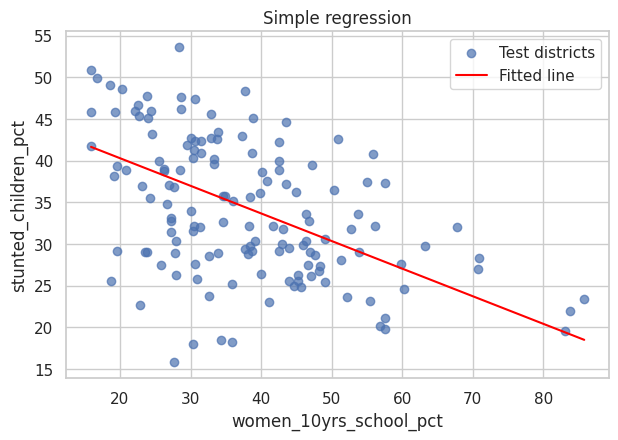

In [36]:
xs = np.linspace(X_test[f1].min(), X_test[f1].max(), 100).reshape(-1,1)
plt.figure(figsize=(7,4.5))
plt.scatter(X_test, y_test, alpha=0.7, label="Test districts")
plt.plot(xs, m1.predict(pd.DataFrame(xs, columns=[f1])), color="red", label="Fitted line")
plt.xlabel(f1); plt.ylabel(TARGET); plt.legend(); plt.title("Simple regression"); plt.show()

**In words:** Schooling alone gives R² = 0.22 and RMSE = 7.3 on the test set. So schooling explains about 22% of the variation in district stunting, and the prediction is typically off by about 7 percentage points. The slope is -0.33: 10 more points of women with 10+ years of schooling goes with about 3.3 points less stunting.

## Part 5 · Multiple regression: eight factors

In [37]:
dm = df.dropna(subset=features + [TARGET]).copy()
print("Districts left:", len(dm), "of", len(df))

X = dm[features]; y = dm[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42)
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
r2_m = r2_score(y_test, pred); rmse_m = mean_squared_error(y_test, pred) ** 0.5
print(f"Multiple model  -> R²: {r2_m:.3f}  RMSE: {rmse_m:.2f}")
print(f"Simple model    -> R²: {r2_1:.3f}  RMSE: {rmse_1:.2f}")
print("Intercept:", round(model.intercept_, 3))

Districts left: 699 of 706
Multiple model  -> R²: 0.450  RMSE: 5.86
Simple model    -> R²: 0.220  RMSE: 7.30
Intercept: 47.205


In [38]:
coef = pd.DataFrame({"feature": features, "coefficient": model.coef_,
                    "corr_with_stunting": [dm[f].corr(dm[TARGET]) for f in features]})
coef["sign_matches_corr"] = np.sign(coef.coefficient) == np.sign(coef.corr_with_stunting)
coef.sort_values("coefficient").round(3).reset_index(drop=True)

,feature,coefficient,corr_with_stunting,sign_matches_corr
0,institutional_births_pct,-0.176,-0.381,True
1,women_10yrs_school_pct,-0.093,-0.544,True
2,health_insurance_pct,-0.038,-0.119,True
3,improved_sanitation_pct,-0.038,-0.505,True
4,adequate_diet_pct,-0.027,-0.230,True
5,clean_cooking_fuel_pct,0.012,-0.417,False
6,child_marriage_pct,0.052,0.426,True
7,women_low_bmi_pct,0.469,0.557,True


**The surprising sign:** `clean_cooking_fuel_pct` has a small positive coefficient (+0.012) even though its correlation with stunting is clearly negative (-0.42). It is the only feature whose sign disagrees. Clean fuel does not really *raise* stunting. In a multiple regression each coefficient means "the effect of this feature holding the other seven fixed". Clean cooking fuel rises together with schooling, sanitation and institutional births (they are all signs of a better-off district), so those features already carry its signal, and what is left over is close to zero and can flip sign by chance. The same overlap explains why the schooling coefficient shrinks from -0.33 (alone) to -0.09 here, and why low BMI (+0.47) is by far the largest coefficient.

**Comparison with Part 4:** with 699 districts, R² rose from 0.22 to 0.45 and RMSE fell from 7.3 to 5.9. Yes, the multiple model improved on the simple one.

## Part 6 · Where is the model most wrong?

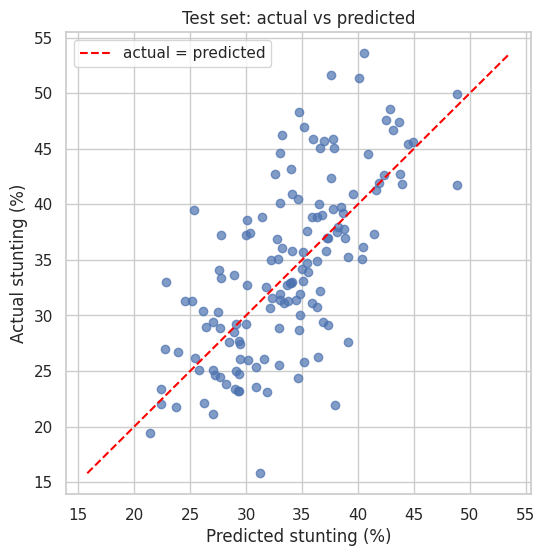

In [39]:
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
plt.figure(figsize=(6,6))
plt.scatter(pred, y_test, alpha=0.7)
plt.plot([lo,hi],[lo,hi], color="red", ls="--", label="actual = predicted")
plt.xlabel("Predicted stunting (%)"); plt.ylabel("Actual stunting (%)")
plt.title("Test set: actual vs predicted"); plt.legend(); plt.show()

In [40]:
dm["predicted"] = model.predict(dm[features])
dm["gap"] = dm[TARGET] - dm["predicted"]
cols = ["state","district",TARGET,"predicted","gap"]
print("More stunting than expected:")
display(dm.sort_values("gap", ascending=False)[cols].head(5).round(1))
print("Doing better than expected:")
display(dm.sort_values("gap")[cols].head(5).round(1))

More stunting than expected:


,state,district,stunted_children_pct,predicted,gap
466,Puducherry,Mahe,48.2,19.9,28.3
404,Meghalaya,West Khasi Hills,59.0,40.6,18.4
280,Karnataka,Yadgir,57.6,40.4,17.2
8,Andhra Pradesh,Kurnool,50.5,35.3,15.2
322,Madhya Pradesh,Katni,49.5,34.9,14.6


Doing better than expected:


,state,district,stunted_children_pct,predicted,gap
337,Madhya Pradesh,Sehore,21.9,37.9,-16.0
24,Arunachal Pradesh,Longding,15.8,31.3,-15.5
300,Madhya Pradesh,Anuppur,24.0,38.5,-14.5
332,Madhya Pradesh,Rajgarh,27.6,41.9,-14.3
378,Maharashtra,Satara,20.2,34.5,-14.3


**Why a District Collector may prefer the gap list:** The "highest stunting" list is mostly districts that are poor on schooling, sanitation and diet, which the Collector already knows and can only change slowly. The gap list shows districts that do *worse than their conditions predict*: for example West Khasi Hills (59.0% actual vs 40.6% predicted), Yadgir (57.6% vs 40.4%) and Kurnool (50.5% vs 35.3%). That points to something specific going wrong, such as delivery of nutrition services or local factors. The negative-gap districts (Sehore, Longding, Anuppur, Rajgarh, Satara) are good places to learn what is working. The biggest gap, Mahe (28 points), is a tiny enclave, so check whether the data is reliable before drawing conclusions.

## Part 7 · A what-if, with care

In [41]:
asp = dm[dm["is_aspirational"] == 1]
row = asp.iloc[[0]].copy()
print("District:", row["district"].iloc[0], "|", row["state"].iloc[0])
before = model.predict(row[features])[0]
row2 = row.copy(); row2["women_10yrs_school_pct"] += 10
after = model.predict(row2[features])[0]
print(f"Schooling: {row['women_10yrs_school_pct'].iloc[0]:.1f}% -> {row2['women_10yrs_school_pct'].iloc[0]:.1f}%")
print(f"Predicted stunting: {before:.1f}% -> {after:.1f}%  (change {after-before:+.2f} points)")
print(f"Actual stunting: {row[TARGET].iloc[0]:.1f}%")

District: Visakhapatnam | Andhra Pradesh
Schooling: 46.0% -> 56.0%
Predicted stunting: 30.9% -> 29.9%  (change -0.93 points)
Actual stunting: 31.0%


**Why this is a rough guide, not a promise:** For Visakhapatnam (Andhra Pradesh, a district with 46% schooling), raising women's schooling by 10 points lowers predicted stunting by only about 0.9 points (30.9% to 29.9%), because the schooling coefficient in the eight-factor model is just -0.09. (1) The model shows association, not cause: schooling moves together with sanitation, diet and income, so raising it alone need not bring this drop, and it would take years to show up. (2) The model's typical error is about 6 points, which is much bigger than a 1 point change, and the data is a 2019-21 survey.

## Part 8 · Answer the questions

In [42]:
factor_corr = corr.drop(["wasted_children_pct", "underweight_children_pct"])
best = factor_corr.abs().idxmax()
print("Strongest single factor (excluding outcome columns):", best, round(factor_corr[best], 3))
print("Multiple regression test R²:", round(r2_m, 3))
top = dm.sort_values("gap", ascending=False).iloc[0]
print("Largest positive gap:", top["district"], "|", top["state"], "| gap =", round(top["gap"], 1))

Strongest single factor (excluding outcome columns): women_low_bmi_pct 0.552
Multiple regression test R²: 0.45
Largest positive gap: Mahe | Puducherry | gap = 28.3


**1. Most strongly linked factor:** Women's low BMI (`women_low_bmi_pct`), correlation +0.55, with women's schooling a close second (-0.54). Underweight children has the highest correlation (+0.70) but it is another outcome, not a factor.

**2. R²:** My multiple regression reached R² = 0.45 on the test set. In plain words, the eight factors together explain about 45% of the differences in stunting between districts; the other 55% comes from things not in the model (and noise). The typical error is about 5.9 percentage points.

**3. Surprising coefficient:** `clean_cooking_fuel_pct` is slightly positive (+0.012) although its correlation with stunting is negative (-0.42). It overlaps strongly with schooling and sanitation, so the model gives its credit to them (the multicollinearity effect from Part 5).

**4. District with much higher stunting than expected:** West Khasi Hills, Meghalaya (59.0% actual vs 40.6% predicted, gap +18.4). Mahe in Puducherry has the largest gap (+28.3), but it is a very small district and the number may be unreliable.

**5. Data-quality problem:** Zeros that really meant "not reported" (plus a "Data Not Available" row, and teen pregnancy values of 91.9% and 80.3% that are not believable). I removed that row, turned zeros into missing values, and dropped incomplete rows only for the columns each model needed (706 districts in Part 4, 699 in Part 5).

## Final insight
Women's low BMI and women's schooling are the factors most strongly linked to district stunting (correlations of +0.55 and -0.54). Eight factors together reach R² = 0.45 (RMSE about 5.9 points) against only R² = 0.22 (RMSE 7.3) for schooling alone, so stunting is better explained by many overlapping factors than by one. The data needed care: a fake "Data Not Available" row, many zeros that meant "not reported", and impossible teen pregnancy values for Chandigarh and Lakshadweep. These results show association, not causation, they use district averages rather than individual children, and the survey is from 2019-21, so a district that raises schooling should not expect exactly the predicted fall. For policy, a Collector should look at districts with large positive gaps such as West Khasi Hills, Yadgir and Kurnool to find out why they do worse than expected, and keep investing in women's nutrition and schooling.